**Práctica 2 — Aplicaciones del Aprendizaje Automático (UD3/UD4)**
**Técnicas usadas (UD3):** Clusterización (K-means), Reducción de dimensionalidad (PCA) y Detección de anomalías (Isolation Forest).
**Autor:** Ana Cascante
**Tecnologías:** Python, scikit-learn, PCA, K-Means, Clustering Jerárquico

**Segmentación de Clientes de E-Commerce mediante Clusterización y PCA**

**1. Descripción del caso de uso**
Contexto (breve): Segmentación de clientes de un e-commerce para personalizar campañas (p. ej., descuentos, retención, cross-sell).  
Objetivo: Identificar grupos de clientes con comportamiento similar (clusters) y detectar clientes atípicos (anomalías) que puedan requerir tratamiento específico (fraude, datos erróneos o comportamientos raros).  
Justificación del uso de Aprendizaje Automático: No hay una variable objetivo (“target”) etiquetada; se busca extraer patrones de similitud, reducir dimensionalidad para visualizar y detectar outliers.


**2. Dataset**
- Origen: (pon aquí la URL o fuente: Kaggle/OpenML/Hugging Face o dataset propio).  
- Tamaño: mínimo 300 registros.  
- Variables: (describe brevemente columnas relevantes).  
- Procesamiento aplicado: nulos, selección de variables, normalización/estandarización.

In [1]:
# Imports 
import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest

import matplotlib.pyplot as plt

In [2]:
# Carga de datos
DATA_PATH = "online_retail_II.csv"  

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
df.head()

Shape: (525461, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [3]:
# 2) Selección y limpieza de variables-

num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

X_raw = df[num_cols].copy()

print("Variables numéricas usadas:", len(num_cols))
X_raw.describe().T.head(10)

Variables numéricas usadas: 3


,count,mean,std,min,25%,50%,75%,max
Quantity,525461.0,10.337667,107.424110,-9600.00,1.00,3.0,10.00,19152.00
Price,525461.0,4.688834,146.126914,-53594.36,1.25,2.1,4.21,25111.09
CustomerID,417534.0,15360.645478,1680.811316,12346.00,13983.00,15311.0,16799.00,18287.00


In [4]:
#3) Preprocesado: imputación + escalado 
preprocess = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

X = preprocess.fit_transform(X_raw)
X.shape

(525461, 3)

In [17]:
# Definir semilla para reproducibilidad
RANDOM_STATE = 42

# Para datasets grandes, hacer un muestreo
# (si tienes < 10,000 registros, puedes comentar este bloque)
if len(X) > 10000:
    from sklearn.model_selection import train_test_split
    X, _ = train_test_split(X, train_size=10000, random_state=RANDOM_STATE)
    print(f"Dataset reducido a {len(X)} registros para optimizar K-means")
else:
    print(f"Usando {len(X)} registros completos")


Dataset reducido a 10000 registros para optimizar K-means


**3. Metodología**
**3.1 Clusterización (K-means)**
- Se prueban varios valores de K.
- Se evalúa con:
  - Inercia (WSS): menor es mejor (método del codo).
  - Coeficiente de silueta: mayor es mejor (selección más robusta).

**3.2 Reducción de dimensionalidad (PCA)**
- Se aplica PCA para:
  - Visualizar en 2D.
  - Reducir ruido y correlación.
- Métrica principal: varianza explicada.

**3.3 Detección de anomalías (Isolation Forest)**
- Se identifican registros atípicos sobre los datos normalizados.
- Se reporta proporción de anomalías y ejemplos.

Probando K-means para diferentes valores de K (dataset: 10000 registros)...
  K=5... Silhouette=0.612 ✓


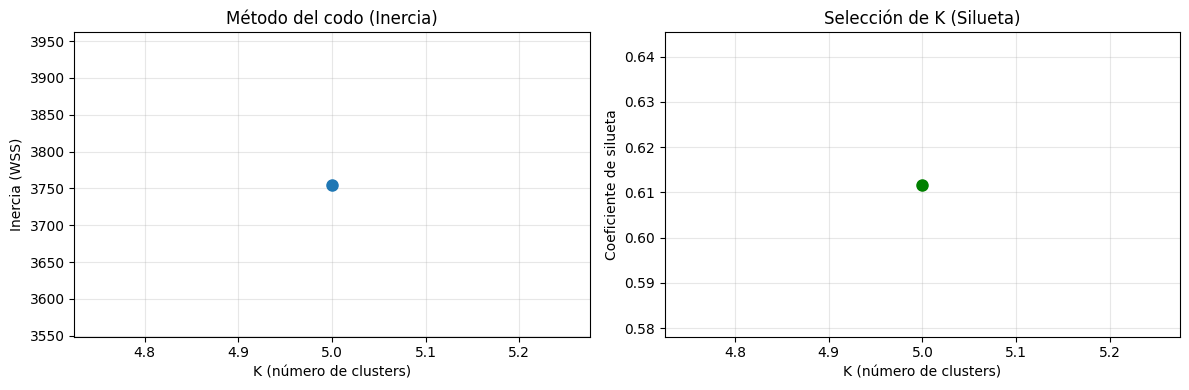


✓ Mejor K seleccionado: 5 (Silhouette=0.612)


5

In [18]:
# K-means: elegir K con inercia + silueta ---
Ks = [5]  
inertias = []
silhouettes = []

print(f"Probando K-means para diferentes valores de K (dataset: {len(X)} registros)...")
for k in Ks:
    print(f"  K={k}...", end=" ", flush=True)
    km = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=100)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X, labels))
    print(f"Silhouette={silhouettes[-1]:.3f} ✓")

# Gráfico inercia
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(list(Ks), inertias, marker="o", linewidth=2, markersize=8)
plt.xlabel("K (número de clusters)")
plt.ylabel("Inercia (WSS)")
plt.title("Método del codo (Inercia)")
plt.grid(True, alpha=0.3)

# Gráfico silueta
plt.subplot(1, 2, 2)
plt.plot(list(Ks), silhouettes, marker="o", linewidth=2, markersize=8, color='green')
plt.xlabel("K (número de clusters)")
plt.ylabel("Coeficiente de silueta")
plt.title("Selección de K (Silueta)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

best_k = int(list(Ks)[int(np.argmax(silhouettes))])
print(f"\n✓ Mejor K seleccionado: {best_k} (Silhouette={max(silhouettes):.3f})")
best_k


In [ ]:
# Entrenar K-means
k = best_k 
kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init="auto")
cluster_labels = kmeans.fit_predict(X)

# IMPORTANTE: Usar solo las filas que corresponden a X (si hubo muestreo)
# Obtener los índices originales antes del preprocesamiento
indices_usados = X_raw.index[:len(X)]#coger los indices correctos
df_result = df.loc[indices_usados].copy()
df_result["cluster"] = cluster_labels

print("K elegido:", k)
print("Silueta final:", silhouette_score(X, cluster_labels))
print(f"Registros con cluster asignado: {len(df_result)}")
df_result["cluster"].value_counts().sort_index()


K elegido: 5
Silueta final: 0.6043225917054786
Registros con cluster asignado: 10000


cluster
0    2703
1       1
2    2429
3    4865
4       2
Name: count, dtype: int64

In [21]:
# Interpretación rápida de clusters (medias por variable)

summary = df_result[num_cols + ["cluster"]].groupby("cluster").mean().T
summary


cluster,0,1,2,3,4
Quantity,12.444321,1.00,9.698230,9.343474,2.000
Price,3.742682,3.75,4.199559,4.928388,4.025
CustomerID,15461.065195,17611.00,15486.335218,15503.596663,17764.000


Varianza explicada (CP1, CP2): [0.8770642  0.09484772] -> total: 0.9719119198559448


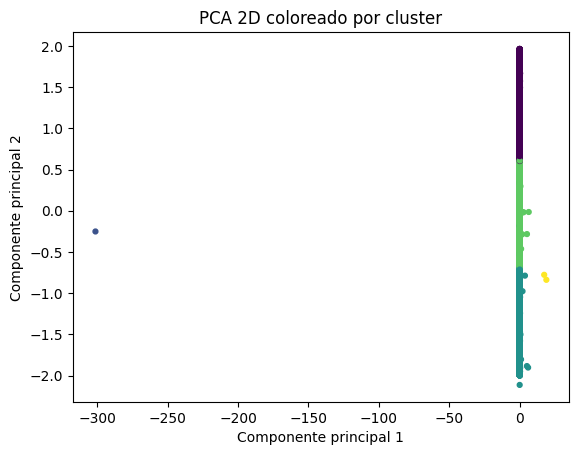

In [22]:
#PCA para visualización en 2D
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca_2d.fit_transform(X)

explained = pca_2d.explained_variance_ratio_
print("Varianza explicada (CP1, CP2):", explained, "-> total:", explained.sum())

plt.figure()
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=cluster_labels, s=12)
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title("PCA 2D coloreado por cluster")
plt.show()


Anomalías detectadas: 290 / 10000 (2.90%)


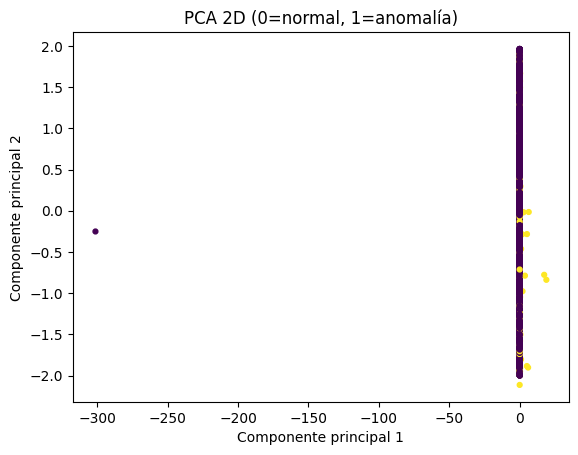

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,cluster,is_anomaly
16,489436,22119,PEACE WOODEN BLOCK LETTERS,3,2009-12-01 09:06:00,6.95,13078.0,United Kingdom,0,True
29,489436,84596L,BISCUITS SMALL BOWL LIGHT BLUE,8,2009-12-01 09:06:00,1.25,13078.0,United Kingdom,0,True
97,489442,22111,SCOTTIE DOG HOT WATER BOTTLE,3,2009-12-01 09:46:00,4.95,13635.0,United Kingdom,3,True
126,489444,POST,POSTAGE,1,2009-12-01 09:55:00,141.00,12636.0,USA,2,True
131,489445,22180,RETRO SPOT LAMP,2,2009-12-01 09:57:00,9.95,17519.0,United Kingdom,0,True
226,489461,21670,BLUE SPOT CERAMIC DRAWER KNOB,24,2009-12-01 10:49:00,1.25,17865.0,United Kingdom,2,True
245,489462,90200E,GREEN SWEETHEART BRACELET,3,2009-12-01 10:49:00,4.25,17592.0,United Kingdom,2,True
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom,2,True
418,489519,79323S,SILVER CHERRY LIGHTS,4,2009-12-01 11:37:00,6.75,17700.0,United Kingdom,0,True
421,489519,21133,PAINTED BIRD ASSORTED CHRISTMAS,12,2009-12-01 11:37:00,1.69,17700.0,United Kingdom,0,True


In [23]:
#Detección de anomalías (Isolation Forest)

iso = IsolationForest(
    n_estimators=300,
    contamination=0.03,
    random_state=RANDOM_STATE
)
anomaly_flag = iso.fit_predict(X) 

df_result["is_anomaly"] = (anomaly_flag == -1)

print("Anomalías detectadas:", df_result["is_anomaly"].sum(), "/", len(df_result),
      f"({df_result['is_anomaly'].mean()*100:.2f}%)")

# Visualización en PCA 2D
plt.figure()
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=df_result["is_anomaly"].astype(int), s=12)
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title("PCA 2D (0=normal, 1=anomalía)")
plt.show()

# Mostrar algunos ejemplos de anomalías
df_result[df_result["is_anomaly"]].head(10)


**4. Resultados**
Incluye aquí, en texto, lo siguiente:
- K elegido y por qué (silueta + codo, o criterio de negocio).
- Silueta final (y una interpretación: valores cerca de 1 mejor separación).
- Varianza explicada de PCA 2D (y si es suficiente para visualizar).
- % de anomalías detectadas (y 2-3 ejemplos de registros atípicos).

**5. Discusión crítica**
El enfoque permite segmentar clientes sin etiquetas y visualizar patrones mediante PCA, pero K-means asume clusters de forma simple y puede ser sensible a outliers y al escalado. Además, PCA reduce dimensionalidad perdiendo parte de la información original. Como mejora, se podría evaluar DBSCAN o clustering jerárquico y realizar una validación con conocimiento de negocio. En un entorno real, un mal uso de la segmentación podría generar recomendaciones o campañas inapropiadas, por lo que sería necesario monitorizar el drift y revisar periódicamente los segmentos.


In [24]:
#Exportar resultados
OUT_PATH = "resultados_con_clusters_y_anomalias.csv"
df_result.to_csv(OUT_PATH, index=False)
print("Guardado:", OUT_PATH)


Guardado: resultados_con_clusters_y_anomalias.csv
